# 플래닝과 시스템 프롬프트

**이 노트북에서 할 일**

1. 할 일 목록 미들웨어가 모델 요청에 더하는 도구·할 일 설명 글·상태 칸을 모델 없이 봅니다.
2. 우리 시스템 메시지 글과 할 일 설명 글이 요청에서 어떤 차례로 합쳐지는지 봅니다.
3. 할 일 목록 없이 한 번, 켜고 한 번 실제 모델로 실행해 할 일 목록과 요청 수를 봅니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 5절과 6절에서 Deep Agent를 한 번씩 실행합니다.
노트북 밖에서 같은 질문을 다섯 번씩 보냈을 때, 5절은 요청 2번, 6절은 4~5번이었습니다.
바깥 호출 한도 10과 서브에이전트 호출 한도 2를 주어, 요청이 끝없이 늘지 않게 막습니다.
요금표로 어림한 예상 비용은 두 실행을 합쳐 0.02달러 아래이고, 청구 금액이 아닙니다.

모델이 적는 할 일 목록과 답 글은 실행마다 달라질 수 있습니다.
걸린 시간은 재지 않았습니다.
읽거나 쓰는 파일은 없습니다.
앞에서 배운 함수 여섯은 도구 파일 `harness_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 넷을 설치합니다.
판은 deepagents 0.7.0과 langchain 1.4.0입니다.
나머지 둘은 `langchain-openai` 1.6.0과 `python-dotenv` 1.2.3입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2·3절을 읽습니다.
할 일 목록 미들웨어가 요청에 무엇을 더하고, 시스템 메시지 글이 어떻게 합쳐지는지 보는 자리입니다.
4~7절은 실제 모델로 두 번 실행하고 견주는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch27-deepagents`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 파란 상자 TodoListMiddleware 인자 없이 하나에서 노란 상자 넷으로 화살표가 갑니다. 첫째는 도구 write_todos 설명 3873자 인자 todos이고, 그 아래 노란 상자 할 일 항목 칸 content와 status, 상태 값 셋 가운데 하나로 이어집니다. 둘째는 노드 TodoListMiddleware.after_model, 셋째는 상태 칸 todos 더해짐, 넷째는 할 일 설명 글 1370자인 그림](attachment:03-1-할-일-목록이-더하는-넷.png)

위에서 아래로 읽습니다.
맨 위 파란 상자는 우리가 만든 미들웨어 객체이고, 노란 상자는 노트북 2·3절 출력으로 확인한 값입니다.
도구 설명과 할 일 설명 글은 모델에게 가는 글이라, 켜면 요청마다 이만큼의 글이 더 실립니다.
맨 위 상자에서 나온 화살표 넷은 미들웨어 하나가 서로 다른 자리에 더하는 것입니다.
왼쪽 아래 상자는 도구 write_todos가 받는 할 일 항목의 모양입니다.
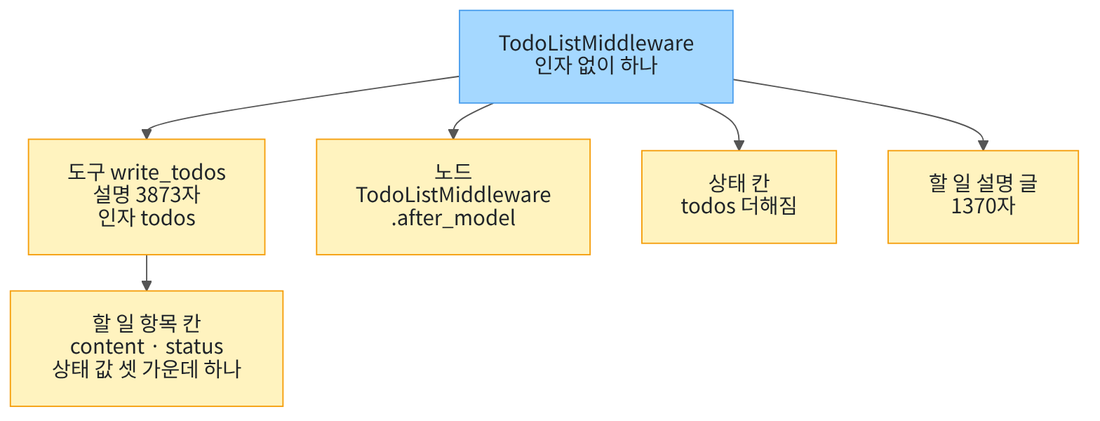

## 1. 준비

이 절에서는 02절의 Deep Agent에 할 일 목록 미들웨어와 우리 시스템 메시지 글을 더합니다.
절 제목의 플래닝은 계획 세우기를 뜻하고, 시스템 프롬프트는 시스템 메시지 글을 가리킵니다.

첫 셀은 패키지 넷을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "deepagents==0.7.0" "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("deepagents:", version("deepagents"))
print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


deepagents: 0.7.0
langchain: 1.4.0
langchain-openai: 1.6.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `deepagents: 0.7.0`과 `langchain: 1.4.0`이 보입니다.
네 판 모두 실습 폴더 잠금과 같은 판입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
미들웨어 `TodoListMiddleware`는 01절 5절에서 조립만 보았고, 이 절에서 실제로 씁니다.
함수 `wrap_model_call`과 미들웨어 `ModelCallLimitMiddleware`는 02절처럼 씁니다.
마지막 가져오기 줄은 02절과 같은 함수 여섯을 도구 파일 `harness_tools.py`에서 가져옵니다.

In [2]:
# Deep Agents(01절)·미들웨어(Ch 22·이 절)·모델(Ch 6 01절)·메시지(Ch 13 04절)·도구(Ch 19 01절) 이름을 가져옵니다
from deepagents import create_deep_agent
from langchain.agents.middleware import ModelCallLimitMiddleware, TodoListMiddleware, wrap_model_call
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from langchain.tools import tool
# 앞 챕터와 01절에서 배운 함수 여섯은 도구 파일에서 가져옵니다(02절과 같은 여섯)
from harness_tools import estimate_cost, names_only_in, show_messages, sum_usage, tool_call_names, tool_names

print("도구 파일에서 가져온 함수:", "estimate_cost, names_only_in, show_messages, sum_usage, tool_call_names, tool_names")

도구 파일에서 가져온 함수: estimate_cost, names_only_in, show_messages, sum_usage, tool_call_names, tool_names


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: estimate_cost, names_only_in, show_messages, sum_usage, tool_call_names, tool_names`가 보입니다.
여섯 함수의 뜻은 02절 1절에 적었습니다.
앞에서 배운 함수는 `harness_tools.py`에 모아 두었고, 파일을 열면 코드를 볼 수 있습니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-28에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
모델 요청은 5절과 6절 실행 셀에서만 나갑니다.

01절에서 본 것처럼, 함수 `create_deep_agent`에는 이 모델 객체를 그대로 넘깁니다.
2·3절은 이 객체로 Deep Agent를 만들기만 하고, 모델을 부르지 않습니다.

## 2. 할 일 목록 미들웨어가 더하는 것

할 일 목록은 모델이 긴 일을 단계로 나눠 적고, 단계마다 상태를 고쳐 적는 목록입니다.
01절에서 한 줄로 정의했고, 이 절에서 본격으로 다룹니다.
deepagents 0.7부터는 Deep Agent의 기본 조립에서 빠져, 쓰려면 미들웨어 `TodoListMiddleware`를 직접 넘깁니다.
01절 5절에서는 이 미들웨어가 노드 하나와 도구 하나를 더하는 것까지 보았습니다.
이 절은 그 미들웨어가 모델에게 가는 요청에 무엇을 더하는지 봅니다.

먼저 견줄 기준 Deep Agent를 02절 3절처럼 만듭니다.

In [5]:
# 01절처럼 인자 없이 Deep Agent를 만들어, 견줄 기준 도구 목록을 얻습니다(요청은 보내지 않음)
base_agent = create_deep_agent(model=model)
base_tools = tool_names(base_agent)
print("기본 도구 수:", len(base_tools))

기본 도구 수: 9


**결과 읽기** — 출력 줄 `기본 도구 수: 9`가 보입니다.
02절 3절 첫 셀과 같은 글이고, 같은 수가 나왔습니다.

다음 셀은 할 일 목록 미들웨어 하나를 넘겨 만들고, 기준과 견줍니다.
실행 전에 예상해 봅니다.
01절 5절처럼 도구 하나와 노드 하나가 더해질 것입니다.

In [6]:
# 할 일 목록 미들웨어 하나를 넘겨 만들고, 기준과 견주어 더해진 도구와 노드를 봅니다(요청은 보내지 않음)
todo_middleware = TodoListMiddleware()
todo_agent = create_deep_agent(model=model, middleware=[todo_middleware])
todo_tools = tool_names(todo_agent)
print("더해진 도구:", names_only_in(base_tools, todo_tools))
base_graph = base_agent.get_graph()
todo_graph = todo_agent.get_graph()
added_nodes = names_only_in(list(base_graph.nodes), list(todo_graph.nodes))
print("더해진 노드:", added_nodes)

더해진 도구: ['write_todos']
더해진 노드: ['TodoListMiddleware.after_model']


**결과 읽기** — 출력 줄 `더해진 도구: ['write_todos']`와 `더해진 노드: ['TodoListMiddleware.after_model']`이 보입니다.
01절 5절 출력과 같습니다.
Ch 22 01절 말로, 더해진 노드는 모델 응답 뒤에 도는 노드형 훅의 자리입니다.
설치판 `todo.py` 286~336행에서 이 훅은 한 응답에 `write_todos` 요청이 둘 이상 들면 모두 오류 도구 메시지로 막습니다.

다음 셀은 미들웨어가 더하는 도구 `write_todos`를 봅니다.
속성 `tools`는 미들웨어가 에이전트에 더하는 도구 목록입니다.
이 도구의 인자는 Ch 19 02절에서 본 입력 형식 클래스(`args_schema`)가 정합니다.
Ch 6 03절 메서드 `model_json_schema()`가 그 형식을 JSON 모양 딕셔너리로 바꿉니다.
그 안의 칸 `$defs`에는 할 일 항목 하나의 양식 `Todo`가 따로 적혀 있습니다.

In [7]:
# 미들웨어가 더하는 도구 write_todos의 이름·설명 길이·인자와, 할 일 항목 하나의 칸을 봅니다
todo_tool = todo_middleware.tools[0]
print("도구 이름:", todo_tool.name)
print("도구 설명 글자 수:", len(todo_tool.description))
print("인자:", list(todo_tool.args))
# 입력 형식 클래스를 JSON 모양 딕셔너리로 바꾸고, 안에 따로 적힌 할 일 항목 양식 Todo의 칸을 꺼냅니다
input_form = todo_tool.args_schema.model_json_schema()
item_fields = input_form["$defs"]["Todo"]["properties"]
print("할 일 항목의 칸:", list(item_fields))
print("상태 칸에 넣을 수 있는 값:", item_fields["status"]["enum"])

도구 이름: write_todos
도구 설명 글자 수: 3873
인자: ['todos']
할 일 항목의 칸: ['content', 'status']
상태 칸에 넣을 수 있는 값: ['pending', 'in_progress', 'completed']


**결과 읽기** — 출력 줄 `도구 이름: write_todos`와 `도구 설명 글자 수: 3873`이 보입니다.
도구 설명은 모델이 읽는 글이라, 이 도구를 켜면 요청마다 이만큼의 글이 함께 실립니다.
라벨 `인자:` 뒤는 `['todos']` 하나이고, 할 일 항목은 칸 `content`와 `status`를 가집니다.
항목의 `status` 값은 `pending`·`in_progress`·`completed` 셋 가운데 하나입니다.
차례로 아직 안 함·하는 중·마침을 뜻하고, Ch 19 02절에서 본 세 글 가운데 하나를 고르는 칸과 같은 모양입니다.

라벨 `상태 칸에 넣을 수 있는 값:`의 상태 칸은 할 일 항목의 칸 `status`를 가리킵니다.
그래프의 상태 칸 `todos`와는 다른 칸입니다.
설치판 `todo.py` 153~164행에서 이 도구는 받은 목록 전체로 상태 칸 `todos`를 바꿔 적습니다.
항목 하나의 상태만 고칠 때도, 모델은 목록 전체를 다시 보냅니다.

다음 셀은 두 Deep Agent가 실행 결과로 내놓는 칸 이름을 견줍니다.
메서드 `get_output_jsonschema()`는 결과 딕셔너리의 칸을 JSON 모양으로 적어 내놓습니다.
칸 이름은 그 딕셔너리의 `properties` 키에 있습니다.

In [8]:
# 두 Deep Agent가 실행 결과로 내놓는 칸 이름을 견주어, 할 일 목록이 더한 상태 칸을 봅니다
base_form = base_agent.get_output_jsonschema()
todo_form = todo_agent.get_output_jsonschema()
base_keys = list(base_form["properties"])
todo_keys = list(todo_form["properties"])
print("기준 결과 칸:", base_keys)
print("더해진 결과 칸:", names_only_in(base_keys, todo_keys))

기준 결과 칸: ['messages', 'structured_response', 'files']
더해진 결과 칸: ['todos']


**결과 읽기** — 출력 줄 `기준 결과 칸: ['messages', 'structured_response', 'files']`와 `더해진 결과 칸: ['todos']`가 보입니다.
할 일 목록은 이 상태 칸 `todos`에 담깁니다.
라벨의 「결과 칸」은 실행 결과에 나오는 상태 칸을 가리킵니다.
설치판 `todo.py` 42행에서 이 칸은 없어도 되는 칸이라, 모델이 `write_todos`를 부르기 전에는 결과에 없습니다.

## 3. 시스템 메시지 글이 붙는 자리

시스템 메시지는 모델에게 역할과 규칙을 먼저 알려 주는 메시지입니다.
Ch 21 01절에서는 함수 `create_agent`의 인자 `system_prompt=`에 이 글을 넘겼습니다.
함수 `create_deep_agent`도 같은 이름의 인자로 받은 글을 시스템 메시지 맨 앞에 둡니다.
이 인자를 주지 않으면, 0.7의 Deep Agent는 빈 시스템 메시지 글로 요청을 보냅니다.
설치판 `graph.py` 912~920행과 독스트링 349~351행에서 확인했고, 5절 실행에서 출력으로 봅니다.

할 일 목록 미들웨어는 이 시스템 메시지에 할 일 설명 글을 붙입니다.
다음 셀은 그 글을 모델에게 보내지 않고, 미들웨어의 속성으로만 읽습니다.

In [9]:
# 할 일 미들웨어가 시스템 메시지에 붙일 안내 글을 속성으로만 읽습니다(모델에게 보내지 않음)
guide_text = todo_middleware.system_prompt
guide_lines = guide_text.splitlines()
print("안내 글 첫 줄:", guide_lines[0])
print("안내 글 글자 수:", len(guide_text))
# 한 응답에 write_todos를 여럿 부르지 말라는 영어 줄이 들어 있는지 봅니다
parallel_rule = "never be called multiple times in parallel"
print("한 응답에 여럿 부르지 말라는 줄이 있는가:", parallel_rule in guide_text)

안내 글 첫 줄: ## `write_todos`
안내 글 글자 수: 1370
한 응답에 여럿 부르지 말라는 줄이 있는가: True


**결과 읽기** — 출력 줄 `안내 글 글자 수: 1370`과 `한 응답에 여럿 부르지 말라는 줄이 있는가: True`가 보입니다.
라벨 `안내 글 첫 줄:` 뒤는 도구 이름을 단 제목 줄입니다.
라벨의 「안내 글」은 이 절에서 부르는 할 일 설명 글입니다.
할 일 설명 글은 영어로, 여러 단계의 일에만 할 일 목록을 쓰고 단계를 마치면 바로 고쳐 적으라고 적습니다.
설치판 `todo.py` 131행이 한 응답에 `write_todos`를 여럿 부르지 말라는 줄입니다.

설치판 `todo.py` 231~256행에서 이 미들웨어는 모델 요청마다 시스템 메시지를 새로 만듭니다.
원래 시스템 메시지 글 뒤에 줄바꿈 둘과 이 할 일 설명 글을 붙입니다.
요청을 감싸는 훅이라, 그래프에 넣어 둔 글은 그대로 두고 나가는 요청만 바꿉니다.

다음 셀은 우리 시스템 메시지 글을 정하고, 그 글을 준 Deep Agent의 조립을 견줍니다.
우리 글은 할 일 목록부터 적으라는 규칙이라, 할 일 목록을 켠 에이전트에만 줍니다.

In [10]:
# 우리 시스템 메시지 글을 정하고, 그 글과 할 일 미들웨어를 함께 넘긴 Deep Agent의 조립을 견줍니다
our_system_text = "당신은 교육센터 자료실 안내를 돕는 도우미입니다. 규정을 여러 개 찾아야 하는 일은 먼저 write_todos로 할 일 목록을 적고 시작하세요. 답은 한국어로 씁니다."
print("우리 글 글자 수:", len(our_system_text))
prompt_agent = create_deep_agent(model=model, system_prompt=our_system_text, middleware=[todo_middleware])
prompt_graph = prompt_agent.get_graph()
print("노드가 같은가:", list(prompt_graph.nodes) == list(todo_graph.nodes))
print("도구가 같은가:", tool_names(prompt_agent) == todo_tools)

우리 글 글자 수: 93
노드가 같은가: True
도구가 같은가: True


**결과 읽기** — 출력 줄 `우리 글 글자 수: 93`, `노드가 같은가: True`, `도구가 같은가: True`가 보입니다.
시스템 메시지 글을 주어도 노드와 도구는 그대로입니다.
시스템 메시지 글은 그래프 모양이 아니라, 요청이 나갈 때마다 실리는 값이기 때문입니다.

실행 전에 예상해 봅니다.
이 에이전트의 요청에 실리는 시스템 메시지 글은 우리 글, 빈 줄, 할 일 설명 글 차례일 것입니다.
글자 수로는 93 + 2 + 1370이고, 6절에서 기록 훅으로 확인합니다.

## 4. 실제 모델을 부를 준비

5·6절에서는 02절의 자료실 규정 도구로 같은 질문을 두 번 실행합니다.
다음 셀은 02절 2절의 규정 글 셀과 같은 글입니다.

In [11]:
# 도구가 찾을 교재용 규정 글 넷을 주제어마다 정합니다(실제 도서관 규정이 아님)
library_rules = {
    "대출": "일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.",
    "연장": "반납 예정일 전에 한 번, 7일 연장할 수 있습니다. 예약한 사람이 있는 책은 연장할 수 없습니다.",
    "연체": "연체한 일수만큼 새 대출이 제한됩니다.",
    "운영": "평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.",
}
print("규정 주제어:", list(library_rules))

규정 주제어: ['대출', '연장', '연체', '운영']


**결과 읽기** — 출력 줄 `규정 주제어: ['대출', '연장', '연체', '운영']`이 보입니다.
02절과 같은 교재용 규정이고, 실제 도서관 규정이 아닙니다.

다음 셀도 02절의 도구 셀과 같은 글입니다.
맨 위 `@tool` 줄이 아래 함수를 도구로 등록하는 것도 02절과 같습니다.

In [12]:
# 주제어 하나로 규정 글 하나를 찾는 도구를 만듭니다(맨 @tool 줄 — Ch 19 01절)
@tool
def lookup_rule(topic: str):
    """교육센터 자료실 규정 하나를 주제어로 찾습니다. topic에는 대출, 연장, 연체, 운영 가운데 하나를 넣습니다."""
    # 없는 주제어면 오류 대신 정해 둔 안내 글을 내놓습니다
    if topic in library_rules:
        return library_rules[topic]
    return "그런 주제어의 규정은 없습니다. 대출, 연장, 연체, 운영 가운데 하나를 넣어 주세요."

**결과 읽기** — 정의 셀이라 출력이 없습니다.
도구 `lookup_rule`은 주제어 하나로 규정 글 하나를 찾고, 없는 주제어에는 정해 둔 글을 내놓습니다.

다음 셀은 바깥 에이전트의 호출 한도입니다.
할 일 목록을 고쳐 적을 때마다 모델 요청이 하나씩 늘어납니다.
그래서 02절의 3보다 넉넉한 10을 줍니다.

In [13]:
# 바깥 에이전트의 모델 요청을 열 번까지로 막는 호출 한도를 만듭니다(02절 셀과 한도만 다름)
outer_limit = ModelCallLimitMiddleware(run_limit=10, exit_behavior="end")
print("바깥 호출 한도:", outer_limit.run_limit)

바깥 호출 한도: 10


**결과 읽기** — 출력 줄 `바깥 호출 한도: 10`이 보입니다.
02절 셀과 한도만 다른 글입니다.

다음 셀은 02절과 같은 글의 general-purpose 명세이고, 자기 호출 한도는 2입니다.
01절에서 본 것처럼 바깥 호출 한도는 이 서브에이전트로 옮겨 가지 않아, 두 곳에 따로 줍니다.

In [14]:
# 기본 서브에이전트와 같은 이름의 명세를 만들고, 그 안에 자기 호출 한도 둘을 넣습니다(01절 6절 모양)
helper_limit = ModelCallLimitMiddleware(run_limit=2, exit_behavior="end")
helper_spec = {
    "name": "general-purpose",
    "description": "교재용 도우미입니다. 맡긴 일을 짧게 처리합니다.",
    "system_prompt": "맡긴 일을 두 문장의 한국어로 처리하세요.",
    "middleware": [helper_limit],
}
print("명세의 키:", list(helper_spec))

명세의 키: ['name', 'description', 'system_prompt', 'middleware']


**결과 읽기** — 출력 줄 `명세의 키: ['name', 'description', 'system_prompt', 'middleware']`가 보입니다.
한 번 실행의 모델 요청은 10에, 도구 `task`를 부른 횟수 × 2를 더한 값을 넘지 않습니다.

다음 셀은 모델 요청마다 시스템 메시지 글과 도구 이름을 적는 기록 훅입니다.
02절 훅 `record_tool_names`에 시스템 메시지 글 기록을 더한 새 판이라, 이름을 `record_request`로 바꿨습니다.
속성 `request.system_message`가 이번 요청의 시스템 메시지이고, 그 속성 `text`가 글입니다.

In [15]:
# 모델 요청이 나갈 때마다, 그 요청의 시스템 메시지 글과 도구 이름을 기록 목록에 붙이는 훅입니다(Ch 22 02절 기록 훅 모양)
@wrap_model_call
def record_request(request, handler):
    seen_system_texts.append(request.system_message.text)
    names = []
    for item in request.tools:
        names.append(item.name)
    seen_tool_lists.append(names)
    # 기록만 하고, 요청은 그대로 모델에게 보냅니다
    return handler(request)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
기록 목록 `seen_system_texts`와 `seen_tool_lists`는 실행 셀마다 새로 만듭니다.
6절에서는 이 훅을 인자 `middleware=` 목록에서 할 일 미들웨어 뒤에 둡니다.
Ch 22 07절에서 본 것처럼 먼저 등록한 미들웨어가 바깥에서 요청을 감쌉니다.
그래서 뒤에 둔 기록 훅은 할 일 설명 글이 붙은 뒤의 요청을 봅니다.

다음 셀은 할 일 목록을 한 줄에 하나씩 출력하는 함수이고, 이 절에서 처음 만듭니다.

In [16]:
# 할 일 목록을 한 줄에 하나씩, 상태와 항목 글로 출력합니다(내놓는 값 없음)
def show_todos(todos):
    for item in todos:
        print(item["status"], "|", item["content"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
할 일 항목 하나는 칸 `content`와 `status`를 가진 딕셔너리입니다.
이 함수는 두 칸을 꺼내 상태, 세로 막대, 항목 글 차례로 한 줄에 출력합니다.

## 5. 할 일 목록 없이 한 번 실행하기

먼저 할 일 목록도 우리 글도 없이, 한도와 기록 훅만 준 Deep Agent를 만듭니다.
02절 `rule_agent`와 같은 모양이고, 바깥 한도와 기록 훅만 다릅니다.

In [17]:
# 할 일 목록도 우리 글도 없이, 우리 도구·호출 한도·기록 훅·명세만 넘겨 Deep Agent를 만듭니다(요청은 아직 보내지 않음)
plain_agent = create_deep_agent(
    model=model,
    tools=[lookup_rule],
    middleware=[outer_limit, record_request],
    subagents=[helper_spec],
)
plain_tools = tool_names(plain_agent)
print("그래프에 등록된 도구 수:", len(plain_tools))
print("write_todos가 있는가:", "write_todos" in plain_tools)

그래프에 등록된 도구 수: 10
write_todos가 있는가: False


**결과 읽기** — 출력 줄 `그래프에 등록된 도구 수: 10`과 `write_todos가 있는가: False`가 보입니다.
기본 도구 아홉과 우리 도구 하나이고, 할 일 도구는 없습니다.

질문은 자료실에 처음 온 학생에게 줄 안내문이고, 규정 셋을 찾아야 답할 수 있습니다.
실행 전에 정한 글이고, 결과를 보고 바꾸지 않았습니다.
입력 딕셔너리 `first_input`은 6절에서도 그대로 다시 씁니다.

In [18]:
# 기록 목록을 새로 만들고, 할 일 목록 없는 Deep Agent에 질문 한 줄을 넣어 한 번 실행합니다
seen_system_texts = []
seen_tool_lists = []
question = "교육센터 자료실에 처음 온 학생에게 줄 안내문을 쓰려고 합니다. 대출, 연장, 연체 규정을 찾아 세 문장으로 정리해 주세요."
first_input = {"messages": [HumanMessage(content=question)]}
input_count = len(first_input["messages"])
plain_result = plain_agent.invoke(first_input)
plain_messages = plain_result["messages"]
print("결과 메시지 수:", len(plain_messages))

결과 메시지 수: 6


**결과 읽기** — 출력 줄 `결과 메시지 수: 6`이 보입니다.
넣은 질문 하나 뒤에 메시지 다섯이 더해졌습니다.

메시지 수는 모델이 도구를 몇 번 고르는지에 따라 달라질 수 있습니다.
노트북 밖에서 같은 질문을 다섯 번 보냈을 때는 다섯 번 모두 여섯이었습니다.

다음 셀은 결과 메시지를 Ch 19 06절 함수 `show_messages`로 봅니다.

In [19]:
# 결과 메시지를 차례로 봅니다(Ch 19 06절 함수 show_messages)
print("결과 메시지:")
show_messages(plain_messages)

결과 메시지:
HumanMessage
AIMessage | 도구 호출 요청: ['lookup_rule', 'lookup_rule', 'lookup_rule']
ToolMessage | 결과 상태: success | 내용: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.
ToolMessage | 결과 상태: success | 내용: 반납 예정일 전에 한 번, 7일 연장할 수 있습니다. 예약한 사람이 있는 책은 연장할 수 없습니다.
ToolMessage | 결과 상태: success | 내용: 연체한 일수만큼 새 대출이 제한됩니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 라벨 줄 아래 둘째 줄이 `AIMessage | 도구 호출 요청: ['lookup_rule', 'lookup_rule', 'lookup_rule']`입니다.
모델이 첫 응답에서 우리 도구를 세 번 함께 요청했습니다.
이어지는 `ToolMessage` 셋은 규정 글이고, 마지막 줄은 도구 요청이 없는 답입니다.

이번 실행에서 세 도구 메시지의 내용은 대출·연장·연체 규정이었습니다.
한 응답에 도구 요청을 몇 개 함께 넣을지는 모델이 정하는 값입니다.
노트북 밖 다섯 번에서도 모두 세 개를 한 응답에 함께 요청했습니다.

다음 셀은 기록 훅이 적은 요청과 상태 칸을 봅니다.
함수 `repr`는 글을 따옴표와 함께 보여 주어, 빈 글도 `''`로 보입니다.

In [20]:
# 기록 훅이 적은 요청 수와 첫 요청의 시스템 메시지 글·받은 도구를 보고, 결과에 todos 칸이 있는지 봅니다
first_plain_text = seen_system_texts[0]
print("기록된 모델 요청 수:", len(seen_system_texts))
print("첫 요청의 시스템 글:", repr(first_plain_text))
print("받은 도구 수:", len(seen_tool_lists[0]))
print("받은 도구에 write_todos가 있는가:", "write_todos" in seen_tool_lists[0])
print("결과에 todos 칸이 있는가:", "todos" in plain_result)

기록된 모델 요청 수: 2
첫 요청의 시스템 글: ''
받은 도구 수: 9
받은 도구에 write_todos가 있는가: False
결과에 todos 칸이 있는가: False


**결과 읽기** — 출력 줄 `기록된 모델 요청 수: 2`와 `첫 요청의 시스템 글: ''`이 보입니다.
우리 글을 주지 않은 Deep Agent는 빈 시스템 메시지 글로 요청을 보냈습니다.
출력 줄 `받은 도구 수: 9`와 `받은 도구에 write_todos가 있는가: False`는 02절과 같은 목록입니다.
출력 줄 `결과에 todos 칸이 있는가: False`도 보입니다.

요청 2번은 도구를 요청한 응답 하나에 마지막 응답 하나를 더한 수입니다.
노트북 밖 다섯 번에서도 모두 2번이었습니다.

## 6. 값 바꿔 보기: 할 일 목록과 우리 글 더하기

바꿀 값은 인자 `system_prompt=`와, 인자 `middleware=` 목록의 할 일 미들웨어입니다.
도구·한도·명세·질문 입력은 5절과 같습니다.
기록 훅은 목록에서 할 일 미들웨어 뒤에 둡니다.

In [21]:
# 같은 부품에 우리 시스템 메시지 글과 할 일 미들웨어를 더해 만듭니다(기록 훅은 할 일 미들웨어 뒤에 둠)
plan_agent = create_deep_agent(
    model=model,
    tools=[lookup_rule],
    system_prompt=our_system_text,
    middleware=[outer_limit, todo_middleware, record_request],
    subagents=[helper_spec],
)
plan_tools = tool_names(plan_agent)
print("그래프에 등록된 도구 수:", len(plan_tools))
print("더해진 도구:", names_only_in(plain_tools, plan_tools))

그래프에 등록된 도구 수: 11
더해진 도구: ['write_todos']


**결과 읽기** — 출력 줄 `그래프에 등록된 도구 수: 11`과 `더해진 도구: ['write_todos']`가 보입니다.
5절 에이전트에 할 일 도구 하나만 더해졌습니다.

실행 전에 예상해 봅니다.
모델이 먼저 `write_todos`로 할 일 목록을 적고, 규정을 찾은 뒤 목록을 고쳐 적을 것입니다.
할 일 목록을 적는 응답이 더해지므로, 모델 요청은 5절보다 늘어날 것입니다.

In [22]:
# 기록 목록을 새로 만들고, 할 일 목록을 켠 Deep Agent에 5절과 같은 질문 입력을 넣어 한 번 실행합니다
seen_system_texts = []
seen_tool_lists = []
plan_result = plan_agent.invoke(first_input)
plan_messages = plan_result["messages"]
print("결과 메시지 수:", len(plan_messages))

결과 메시지 수: 12


**결과 읽기** — 라벨 `결과 메시지 수:` 뒤에 이번 실행의 메시지 수가 보입니다.
5절의 여섯보다 메시지가 늘었습니다.

이번 실행에서는 `결과 메시지 수: 12`였습니다.
할 일 목록을 고쳐 적은 횟수에 따라 달라지는 값이라, 다시 실행하면 바뀔 수 있습니다.
새 커널로 한 번 더 실행했을 때는 10이었습니다.

다음 셀은 결과 메시지를 차례로 봅니다.

In [23]:
# 결과 메시지를 차례로 봅니다(Ch 19 06절 함수 show_messages)
print("결과 메시지:")
show_messages(plan_messages)

결과 메시지:
HumanMessage
AIMessage | 도구 호출 요청: ['write_todos']
ToolMessage | 결과 상태: success | 내용: Updated todo list to [{'content': '대출 규정 확인', 'status': 'in_progress'}, {'content': '연장 규정 확인', 'status': 'pending'}, {'content': '연체 규정 확인', 'status': 'pending'}, {'content': '세 문장 안내문으로 정리', 'status': 'pending'}]
AIMessage | 도구 호출 요청: ['lookup_rule', 'lookup_rule', 'lookup_rule']
ToolMessage | 결과 상태: success | 내용: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.
ToolMessage | 결과 상태: success | 내용: 반납 예정일 전에 한 번, 7일 연장할 수 있습니다. 예약한 사람이 있는 책은 연장할 수 없습니다.
ToolMessage | 결과 상태: success | 내용: 연체한 일수만큼 새 대출이 제한됩니다.
AIMessage | 도구 호출 요청: ['write_todos']
ToolMessage | 결과 상태: success | 내용: Updated todo list to [{'content': '대출 규정 확인', 'status': 'completed'}, {'content': '연장 규정 확인', 'status': 'completed'}, {'content': '연체 규정 확인', 'status': 'completed'}, {'content': '세 문장 안내문으로 정리', 'status': 'in_progress'}]
AIMessage | 도구 호출 요청: ['write_todos']
ToolMessage | 결과 상태: success | 내용: Updated todo list to [{'content': '대출 규

**결과 읽기** — 라벨 줄 아래 둘째 줄이 `AIMessage | 도구 호출 요청: ['write_todos']`입니다.
모델이 첫 응답에서 할 일 목록부터 적었습니다.
바로 아래 `ToolMessage`의 내용은 `Updated todo list to`로 시작하는 도구 결과입니다.

이번 실행에서 모델은 규정 셋을 한 응답에 함께 찾은 뒤, `write_todos`를 두 번 더 불렀습니다.
한 번은 세 규정 항목을 `completed`로, 마지막 항목을 `in_progress`로 고쳐 적었습니다.
다음 번에는 마지막 항목까지 `completed`로 고쳐 적고 답했습니다.
할 일 항목 글과 고쳐 적은 횟수는 모델이 정하는 값이라, 실행마다 달라질 수 있습니다.

다음 셀은 이번 실행이 더한 응답마다 `write_todos`와 `task` 요청 수를 셉니다.

In [24]:
# 넣은 메시지 뒤, 이번 실행이 더한 응답마다 write_todos와 task 요청 수를 셉니다(Ch 19 04절 함수 tool_call_names)
plan_new = plan_messages[input_count:]
todo_counts = []
task_counts = []
for message in plan_new:
    if type(message).__name__ == "AIMessage":
        names = tool_call_names(message)
        todo_counts.append(names.count("write_todos"))
        task_counts.append(names.count("task"))
print("응답마다 write_todos 요청 수:", todo_counts)
print("응답마다 task 요청 수:", task_counts)

응답마다 write_todos 요청 수: [1, 0, 1, 1, 0]
응답마다 task 요청 수: [0, 0, 0, 0, 0]


**결과 읽기** — 라벨 `응답마다 write_todos 요청 수:` 뒤 목록의 수는 모두 0 또는 1입니다.
한 응답에 `write_todos`를 둘 이상 요청한 적이 없어, 오류 도구 메시지도 없었습니다.
라벨 `응답마다 task 요청 수:` 뒤는 모두 0이라, general-purpose 서브에이전트는 실행되지 않았습니다.

이번 실행에서는 `응답마다 write_todos 요청 수: [1, 0, 1, 1, 0]`이었습니다.
새 커널로 한 번 더 실행했을 때는 `[1, 0, 1, 0]`으로, 응답이 하나 적었습니다.
노트북 밖 다섯 번에서는 앞 모양이 네 번, 뒤 모양이 한 번이었습니다.

다음 셀은 결과의 상태 칸 `todos`를 봅니다.

In [25]:
# 결과의 상태 칸 todos에서, 모델이 마지막으로 적은 할 일 목록을 봅니다(칸이 없으면 있는가만 출력)
print("결과에 todos 칸이 있는가:", "todos" in plan_result)
if "todos" in plan_result:
    print("할 일 목록:")
    show_todos(plan_result["todos"])

결과에 todos 칸이 있는가: True
할 일 목록:
completed | 대출 규정 확인
completed | 연장 규정 확인
completed | 연체 규정 확인
completed | 세 문장 안내문으로 정리


**결과 읽기** — 출력 줄 `결과에 todos 칸이 있는가: True`가 보입니다.
라벨 줄 `할 일 목록:` 아래가 모델이 마지막으로 적은 목록이고, 한 줄에 상태와 항목 글이 하나씩 있습니다.
모델이 `write_todos`를 불러, 5절에는 없던 상태 칸이 생겼습니다.

이번 실행에서는 항목 넷이 모두 `completed`였습니다.
항목 글·수·상태는 모델이 적은 값이라, 실행마다 달라질 수 있습니다.
한 번 더 실행했을 때와 노트북 밖 한 번은 마지막 항목을 `in_progress`로 둔 채 답했습니다.
상태 `completed`는 모델이 적은 표시일 뿐, 일을 바르게 했다는 확인이 아닙니다.

다음 셀은 기록 훅이 적은 첫 요청의 시스템 메시지 글을 봅니다.

In [26]:
# 첫 요청의 시스템 메시지 글이 우리 글·빈 줄·할 일 안내 글 차례로 이루어졌는지 봅니다
first_plan_text = seen_system_texts[0]
print("첫 요청 시스템 글 글자 수:", len(first_plan_text))
print("우리 글로 시작하는가:", first_plan_text.startswith(our_system_text))
print("할 일 안내 글로 끝나는가:", first_plan_text.endswith(guide_text))
# 줄바꿈 둘("\n\n")이 빈 줄 하나를 만듭니다
joined_text = our_system_text + "\n\n" + guide_text
print("우리 글 + 빈 줄 + 안내 글과 같은가:", first_plan_text == joined_text)

첫 요청 시스템 글 글자 수: 1465
우리 글로 시작하는가: True
할 일 안내 글로 끝나는가: True
우리 글 + 빈 줄 + 안내 글과 같은가: True


**결과 읽기** — 출력 줄 `첫 요청 시스템 글 글자 수: 1465`가 보입니다.
출력 줄 `우리 글로 시작하는가: True`와 `할 일 안내 글로 끝나는가: True`도 보입니다.
마지막 줄 `우리 글 + 빈 줄 + 안내 글과 같은가: True`는 두 글이 이 차례로만 이어졌다는 뜻입니다.
3절에서 예상한 93 + 2 + 1370과 같은 글자 수입니다.

다음 셀은 요청마다 시스템 메시지 글이 같았는지와, 모델이 받은 도구를 봅니다.

In [27]:
# 요청마다 시스템 메시지 글이 첫 요청과 같은지 보고, 모델이 받은 도구를 봅니다
for text in seen_system_texts:
    print("이 요청의 시스템 글이 같은가:", text == first_plan_text)
first_tools = seen_tool_lists[0]
print("받은 도구 수:", len(first_tools))
print("write_todos를 받았는가:", "write_todos" in first_tools)
print("execute를 받았는가:", "execute" in first_tools)

이 요청의 시스템 글이 같은가: True
이 요청의 시스템 글이 같은가: True
이 요청의 시스템 글이 같은가: True
이 요청의 시스템 글이 같은가: True
이 요청의 시스템 글이 같은가: True
받은 도구 수: 10
write_todos를 받았는가: True
execute를 받았는가: False


**결과 읽기** — `이 요청의 시스템 글이 같은가: True` 줄이 요청 수만큼 보입니다.
할 일 설명 글은 첫 요청에만이 아니라, 요청마다 붙었습니다.
출력 줄 `받은 도구 수: 10`, `write_todos를 받았는가: True`, `execute를 받았는가: False`도 보입니다.
02절에서 모델이 받은 도구 아홉에 `write_todos`가 더해진 목록입니다.

## 7. 요청 수와 입력 토큰

이 실행도 도구 `task`를 부르지 않아, 모델 요청은 모두 바깥 에이전트의 것입니다.
02절처럼 응답으로 센 요청 수와 기록 훅이 센 요청 수를 견줍니다.

In [28]:
# 이번 실행이 더한 메시지만 Ch 19 05절 함수 sum_usage로 세고, 기록 훅이 센 요청 수와 견줍니다
plan_usage = sum_usage(plan_new)
print("응답으로 센 요청 수:", plan_usage["requests"])
print("기록 훅이 센 요청 수:", len(seen_system_texts))
print("입력 토큰:", plan_usage["input_tokens"], "| 출력 토큰:", plan_usage["output_tokens"])

응답으로 센 요청 수: 5
기록 훅이 센 요청 수: 5
입력 토큰: 17048 | 출력 토큰: 344


**결과 읽기** — 라벨 `응답으로 센 요청 수:`와 `기록 훅이 센 요청 수:` 뒤의 수가 같습니다.
요청 수는 도구를 요청한 응답 수에 마지막 응답 하나를 더한 값입니다.
도구 `write_todos`를 부르는 응답도 도구를 요청한 응답이라 한 번씩 셉니다.

이번 실행에서는 요청 5번, `입력 토큰: 17048 | 출력 토큰: 344`였습니다.
도구 `write_todos`를 두 번 부르면 요청 4, 세 번 부르면 요청 5가 됩니다.
한 번 더 실행했을 때는 두 번 불러 요청 4번이었습니다.
앞 메시지가 쌓이므로, 뒤 요청일수록 실리는 글이 깁니다.

두 실행의 첫 요청은 모델 응답이 섞이기 전이라, 실행마다 같은 글이 나갑니다.
그래서 첫 요청의 입력 토큰을 견주면 5절과 6절 설정의 차이만 봅니다.
다음 셀은 두 실행의 첫 응답 사용량에서 입력 토큰을 꺼냅니다.

In [29]:
# 두 실행의 첫 응답 사용량에서, 첫 요청의 입력 토큰을 꺼내 견줍니다
plain_first = plain_messages[input_count].usage_metadata
plan_first = plan_messages[input_count].usage_metadata
print("할 일 목록 없이, 첫 요청 입력 토큰:", plain_first["input_tokens"])
print("할 일 목록을 켜고, 첫 요청 입력 토큰:", plan_first["input_tokens"])
added_tokens = plan_first["input_tokens"] - plain_first["input_tokens"]
print("늘어난 입력 토큰:", added_tokens)

할 일 목록 없이, 첫 요청 입력 토큰: 1874
할 일 목록을 켜고, 첫 요청 입력 토큰: 3106
늘어난 입력 토큰: 1232


**결과 읽기** — 할 일 목록을 켠 쪽의 첫 요청 입력 토큰이 더 큽니다.
라벨 `늘어난 입력 토큰:` 뒤가 두 값의 차이입니다.
늘어난 입력에는 우리 글 93자, 할 일 설명 글 1370자, 도구 설명 3873자가 함께 들어 있습니다.

이번 실행에서는 `할 일 목록 없이, 첫 요청 입력 토큰: 1874`였습니다.
할 일 목록을 켠 쪽은 `할 일 목록을 켜고, 첫 요청 입력 토큰: 3106`이었습니다.
새 커널 두 번과 노트북 밖 다섯 번에서 모두 같은 값이었습니다.
다만 토큰 수는 서비스가 세는 값이라, 모델이나 판이 바뀌면 달라질 수 있습니다.

다음 셀은 Ch 6 06절 함수 `estimate_cost`로 6절 실행의 예상 비용을 셉니다.
요금은 과정 요금표(2026-09-17)의 100만 토큰당 달러이고, 예상 비용은 청구 금액이 아닙니다.

In [30]:
# 2026-09-17 요금표(100만 토큰당 달러)로 6절 실행의 예상 비용을 셉니다(Ch 6 06절 함수 estimate_cost)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
plan_cost = estimate_cost(plan_usage, input_rate, cached_input_rate, output_rate)
rounded_cost = round(plan_cost, 6)
print("예상 비용(달러):", rounded_cost)

예상 비용(달러): 0.014334


**결과 읽기** — 라벨 `예상 비용(달러):` 뒤에 6절 실행의 어림값이 보입니다.
토큰 수가 실행마다 달라, 이 값도 달라질 수 있습니다.
합친 사용량에는 캐시 입력 칸이 없어, 입력 토큰을 모두 입력 요금으로 셉니다.

이번 실행에서는 `예상 비용(달러): 0.014334`였습니다.
한 번 더 실행했을 때는 요청이 하나 적어 0.01127이었습니다.
캐시 입력을 빼지 않은 어림이라, 청구 금액은 이보다 작을 수 있습니다.

## 정리

1. 할 일 목록 미들웨어는 도구 `write_todos`, 노드 하나, 상태 칸 `todos`, 시스템 메시지에 붙는 할 일 설명 글을 더합니다.
2. 우리 글을 주지 않은 요청의 시스템 메시지 글은 빈 글이었습니다. 할 일 미들웨어는 요청마다 우리 글 뒤에 할 일 설명 글을 붙였습니다.
3. 할 일 목록을 켠 실행에서도 요청 수는 도구를 요청한 응답 수에 1을 더한 값이었습니다.

04절에서는 중간 결과를 파일로 적어 두는 장면을, 디스크에 쓰는 백엔드와 상태 칸에 두는 백엔드로 견줍니다.